# Run PLSes

This script is for taking connectomes and running PLS-SVD to exctract connectivity signatures. Permutations testing determines the number of components and bootstrapping is used to identify stable variables. 

Example data is provided in order to run the code. All original data is avaliable on the NBDC Data Hub (https://www.nbdc-datahub.org/).

Written by: Alexa Mousley (alexa.mousley@mrc-cbu.cam.ac.uk)
*October 2026*

In [1]:
### Import packages ###

from A_config import  *                          # Import custom paths
from A_functions import *                          # Custom functions/colors
import os                                        # For combining paths
import numpy as np                               # Basic requirements 
import pandas as pd                              # Basic requirements
import bct as bct                                # Network statistics
from scipy.stats import pearsonr                 # Correlation for LVs

In [ ]:
### Import data ###

# Associated data
associated_data = pd.read_csv(os.path.join(data_dir,"associated_data_example.csv"))

# Subsample associated data
subsample_associated_data = pd.read_csv(os.path.join(data_dir,"subsample_associated_data_example.csv"))

# Networks
all_connectomes =  np.load(os.path.join(data_dir, "connectomes.npz"))['connectomes']
# Pull only networks for those with matching associated data
connectomes = all_connectomes[:,:,associated_data['imaging_index'].values]
nnodes, _, nsub = connectomes.shape # Define number of nodes and number of participants

# Pull networks for genetics subsample
subsample_index = associated_data['imaging_index'].isin(subsample_associated_data['imaging_index'])
# Pull only networks for those with matching genetic data
subsample_connectomes = all_connectomes[:,:,subsample_associated_data['imaging_index'].values]
_, _, subsample_nsub = subsample_connectomes.shape # Define number of participants in subsample

# Load permutation & bootstrapping data if already run (or plotting examples)
pls_x_weights = pd.read_csv(os.path.join(data_dir,"pls_x_weights_example.csv"))
pls_y_weights = pd.read_csv(os.path.join(data_dir,"pls_y_weights_example.csv"))
subsample_pls_y_weights = pd.read_csv(os.path.join(data_dir,"subsample_pls_y_weights_example.csv"))
subsample_pls_x_weights = pd.read_csv(os.path.join(data_dir,"subsample_pls_x_weights_example.csv"))

In [3]:
### Set up data (just so it's easy to pull later) ###

# Mental health
mental_health = associated_data['mental_health_score'].values

# Adversity data
adversity_labels = ['Household_Community_Instability','Physical_Sexual_Abuse','Parental_Neglect','Financial_Difficulties']
adversity = associated_data[adversity_labels].values

# PGS
pgs_labels = subsample_associated_data.loc[:, 'CT':'VasDem'].columns.tolist()
pgs = subsample_associated_data[pgs_labels]

# Number of possible edges
n_edges = int((nnodes*(nnodes-1))/2)   

In [4]:
### Turn connectomes into vectors ###

'''
Note: in the example connectomes, there are no zeros for everyone so the print out will show
that all 30,135 edges are kept for PLSes.
'''
 
# Initialize connectome vectors
conn_vectors = np.zeros((nsub, n_edges)) 
# Vectorize
conn_vectors[:] = np.array([vectorize(connectomes[:, :, i]) for i in range(nsub)])
# Confirm vectorization worked
assert conn_vectors.shape[1] == n_edges, "Vector is not the correct shape"

# Filter out all zero connections 
zero_mask = (conn_vectors == 0).all(axis=0)               # Mask connections that are zero for everyone
conn_vectors = conn_vectors[:, ~zero_mask]                # Remove edges that are all zeros
print(f"Vector shape for adveristy, cognition and mental health PLSes (X): {conn_vectors.shape}")

### Repeat with subsample data ###
subsample_conn_vectors = np.zeros((subsample_nsub, n_edges))    # Initialize connectome vectors
subsample_conn_vectors[:] = np.array([vectorize(subsample_connectomes[:, :, i]) for i in range(subsample_nsub)])
assert subsample_conn_vectors.shape[1] == n_edges, "Vector is not the correct shape"

# Filter out all zero connections 
genetics_zero_mask = (subsample_conn_vectors == 0).all(axis=0)              # Mask connections that are zero for everyone
subsample_conn_vectors = subsample_conn_vectors[:, ~genetics_zero_mask]     # Remove edges that are all zeros
print(f"Vector shape for genetics PLS (X): {subsample_conn_vectors.shape}")

Vector shape for adveristy, cognition and mental health PLSes (X): (7384, 21474)
Vector shape for genetics PLS (X): (3914, 19886)


In [5]:
### Run permutations ###

"""
Because of how large the data is (X), this section will take a few minutes to run (~ 5 minutes) 
"""

# Define Y
Y = adversity
y_labels = adversity_labels
X = conn_vectors
x_label = range(len(X))

# Print shapes
print(f"Shape of X: {X.shape}")
print(f"Shape of Y: {Y.shape}")

# Run permutations
obs_singular_vals, perms, pvals = pls_permutations(X, Y, n_perms=5000)

Shape of X: (7384, 21474)
Shape of Y: (7384, 4)


Permutations: 100%|██████████| 5000/5000 [01:32<00:00, 54.24it/s]


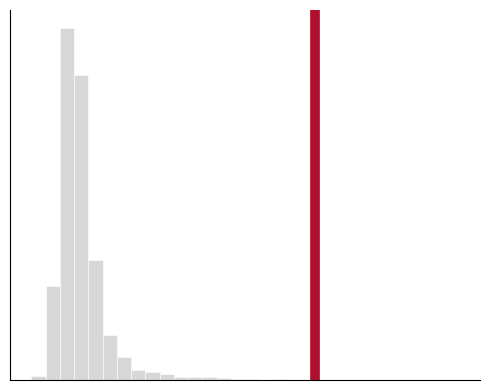

Significant LVs (p < 0.05): [1, 4]


In [6]:
### Figure 2c ###

plot_permutation_results(obs_singular_vals, perms, pvals, n_plot=1, name='adversity_perm', save_path=save_dir)

# Keep significant LVs (e.g., p < 0.05)
sig_idx = [i for i, p in enumerate(pvals) if p < 0.05]
sig_comp = [i + 1 for i in sig_idx]  # Convert to 1-based indexing
print(f"Significant LVs (p < 0.05): {sig_comp}")

In [7]:
### Re-run PLS with specific number of components ###

n_comp = 1

# Run PLS-SVD with specific number of components
svd_model, x_scores, y_scores = run_pls_svd(X, Y, n_components=n_comp)

In [8]:
### Run bootstrapping ###

"""
Because of how large the data is (X), this code will take A WHILE to run (~ 1 hour)
If you have already run this code, or want to use our example data, you can import 
the results above and skip to the next section.
"""

# Bootstrap for X
obs_x_weights, x_weights_bsr, x_weights_boot, x_weights_se = pls_bootstraps(X, Y, n_components=1,which="x",n_boot=10000)

# Bootstrap for Y
obs_y_weights, y_weights_bsr, y_weights_boot, y_weights_se = pls_bootstraps(X, Y, n_components=1,which="y",n_boot=10000)

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

  0%|          | 0/10000 [00:00<?, ?it/s]

Number of stable variables: 5140 out of 21474


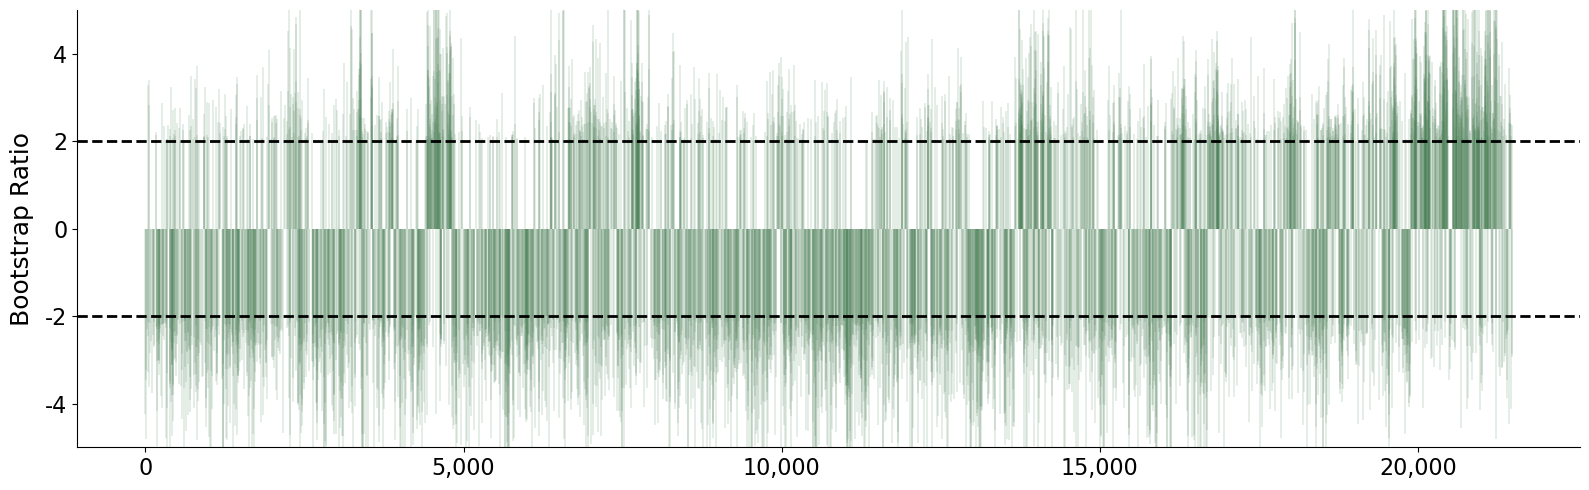

Number of stable variables: 2 out of 4


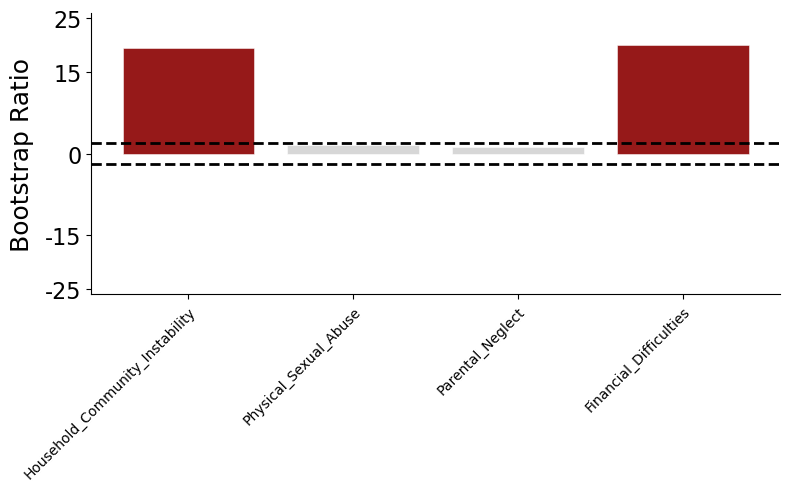

In [9]:
### Figure 2c ###

# Plot X
plot_X_bsr(pls_x_weights['Adver_LV1_bsr'],lv=1,name='Adversity_LV1X_boot',save_path=save_dir)

# Plot Y
plot_Y_bsr(pls_y_weights['Adver_LV1_bsr'],lv=1,feature_names=y_labels,name='Adversity_LV1Y_boot',save_path=save_dir)


In [12]:
### Save masks ###

# First mask edges that are stable
print(f"Adversity shape: {pls_x_weights['Adver_LV1_weight'].shape}")
adversity_bsr_mask = np.abs(pls_x_weights['Adver_LV1_bsr']) > 2
adversity_masked_weights = np.where(adversity_bsr_mask, pls_x_weights['Adver_LV1_weight'], 0)
print(f"Adversity stable edges: {np.count_nonzero(adversity_masked_weights)}")

print(f"Mental health shape: {pls_x_weights['MH_LV1_weight'].shape}")
mental_health_bsr_mask = np.abs(pls_x_weights['MH_LV1_bsr']) > 2
mental_health_masked_weights = np.where(mental_health_bsr_mask, pls_x_weights['MH_LV1_weight'], 0)
print(f"Mental health stable edges: {np.count_nonzero(mental_health_masked_weights)}")

print(f"Cognition shape: {pls_x_weights['Cog_LV1_weight'].shape}")
cognitive_bsr_mask = np.abs(pls_x_weights['Cog_LV1_bsr']) > 2
cognitive_masked_weights = np.where(cognitive_bsr_mask, pls_x_weights['Cog_LV1_weight'], 0)
print(f"Cognition stable edges: {np.count_nonzero(cognitive_masked_weights)}")

print(f"Genetics LV1 shape: {subsample_pls_x_weights['genetic_LV1_weight'].shape}")
gene_LV1_bsr_mask = np.abs(subsample_pls_x_weights['genetic_LV1_bsr']) > 2
gene_LV1_masked_weights = np.where(gene_LV1_bsr_mask, subsample_pls_x_weights['genetic_LV1_weight'], 0)
print(f"Genetics LV1 stable edges: {np.count_nonzero(gene_LV1_masked_weights)}")

print(f"Genetics LV2 shape: {subsample_pls_x_weights['genetic_LV2_weight'].shape}")
gene_LV2_bsr_mask = np.abs(subsample_pls_x_weights['genetic_LV2_bsr']) > 2
gene_LV2_masked_weights = np.where(gene_LV2_bsr_mask, subsample_pls_x_weights['genetic_LV2_weight'], 0)
print(f"Genetics LV2 stable edges: {np.count_nonzero(gene_LV2_masked_weights)}")

# Then, convert vectors back to matrices
adversity_edge_matrix = convert_to_matrix(adversity_masked_weights,nnodes,n_edges,zero_mask)
genetics_LV1_edge_matrix = convert_to_matrix(gene_LV1_masked_weights,nnodes,n_edges,genetics_zero_mask)
genetics_LV2_edge_matrix = convert_to_matrix(gene_LV2_masked_weights,nnodes,n_edges,genetics_zero_mask)
cognitive_edge_matrix = convert_to_matrix(cognitive_masked_weights,nnodes,n_edges,zero_mask)
mental_health_edge_matrix = convert_to_matrix(mental_health_masked_weights,nnodes,n_edges,zero_mask)

# Save
# np.save(os.path.join(data_dir,"adversity_edge_matrix.npy"),adversity_edge_matrix)
# np.save(os.path.join(data_dir,"cognitive_edge_matrix.npy"),cognitive_edge_matrix)
# np.save(os.path.join(data_dir,"mental_health_edge_matrix.npy"),mental_health_edge_matrix)
# np.save(os.path.join(data_dir,"genetics_LV1_edge_matrix.npy"),genetics_LV1_edge_matrix)
# np.save(os.path.join(data_dir,"genetics_LV2_edge_matrix.npy"),genetics_LV2_edge_matrix)

Adversity shape: (21474,)
Adversity stable edges: 5140
Mental health shape: (21474,)
Mental health stable edges: 5704
Cognition shape: (21474,)
Cognition stable edges: 5239
Genetics LV1 shape: (19886,)
Genetics LV1 stable edges: 4479
Genetics LV2 shape: (19886,)
Genetics LV2 stable edges: 4189
